In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("/content/drive/MyDrive/WeIntern/Task2/cleaned_retail_orders.csv")

# Convert Order Date into a proper date format
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Inspect column names and data types
df.info()

,Order ID,Customer Name,Gender,Age,City,Product Category,Quantity,Unit Price (INR),Discount %,Payment Method,Order Date,Customer Rating,Coupon Code,Coupon Code Clean,Customer Name Clean,City Clean,Discount Clean
0,ORD1392,Customer 147,Female,32.0,Bengaluru,Furniture,2,1042.10,0.0,Cash on Delivery,2025-02-25,2.0,NaN,NO COUPON RECORDED,Customer 147,Bengaluru,0.0
1,ORD1976,Customer 39,Female,13.0,Mumbai,Groceries,7,715.80,10.0,Credit Card,2025-09-25,2.0,SAVE10,SAVE10,Customer 39,Mumbai,10.0
2,ORD1457,Customer 253,Male,37.0,Delhi,Electronics,7,787.70,20.0,Credit Card,2025-09-29,4.0,NaN,NO COUPON RECORDED,Customer 253,Delhi,20.0
3,ORD1239,Customer 251,Male,35.0,Hyderabad,Clothing,7,1223.53,0.0,Credit Card,2025-05-12,1.0,NaN,NO COUPON RECORDED,Customer 251,Hyderabad,0.0
4,ORD1440,Customer 389,Female,42.0,Bengaluru,Electronics,1,1112.13,20.0,Debit Card,2025-03-13,2.0,NaN,NO COUPON RECORDED,Customer 389,Bengaluru,20.0


Number of rows: 1000
Number of columns: 17
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Order ID             1000 non-null   object        
 1   Customer Name        964 non-null    object        
 2   Gender               957 non-null    object        
 3   Age                  1000 non-null   float64       
 4   City                 971 non-null    object        
 5   Product Category     1000 non-null   object        
 6   Quantity             1000 non-null   int64         
 7   Unit Price (INR)     1000 non-null   float64       
 8   Discount %           903 non-null    float64       
 9   Payment Method       935 non-null    object        
 10  Order Date           971 non-null    datetime64[ns]
 11  Customer Rating      739 non-null    float64       
 12  Coupon Code          120 non-null    object     

## Data Quality and Missing Value Analysis

This section examines missing values, duplicate records and unique values in the cleaned retail orders dataset. The objective is to identify any remaining data-quality issues before performing statistical analysis and visualization.


In [ ]:
# Calculate missing values in each column
missing_count = df.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage.round(2)
})

# Display columns with missing values first
missing_summary = missing_summary.sort_values(
    "Missing Percentage (%)",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage (%)
Coupon Code,880,88.0
Customer Rating,261,26.1
Discount %,97,9.7
Discount Clean,97,9.7
Payment Method,65,6.5
Gender,43,4.3
Customer Name,36,3.6
Order Date,29,2.9
City,29,2.9
Order ID,0,0.0


In [ ]:
# Check exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Count unique values in each column
unique_summary = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes.astype(str)
})

display(unique_summary)

Duplicate rows: 0


,Unique Values,Data Type
Order ID,1000,object
Customer Name,363,object
Gender,2,object
Age,58,float64
City,7,object
Product Category,5,object
Quantity,13,int64
Unit Price (INR),998,float64
Discount %,5,float64
Payment Method,4,object


## Descriptive Statistical Analysis

Descriptive statistical analysis is used to summarize the main characteristics of the retail orders dataset. Measures such as mean, median, standard deviation, quartiles, minimum and maximum help us understand typical values, variability and potential extreme observations.

The analysis covers numerical variables such as Age, Quantity, Unit Price (INR), Discount Clean and Customer Rating. Categorical variables such as Gender, Product Category, City Clean and Payment Method will be examined using frequency counts and category summaries.


In [ ]:
# Select the main numerical columns for analysis
numeric_cols = [
    "Age",
    "Quantity",
    "Unit Price (INR)",
    "Discount Clean",
    "Customer Rating"
]

# Calculate descriptive statistics
numeric_summary = df[numeric_cols].describe().T

# Add the median as an explicit column
numeric_summary["median"] = df[numeric_cols].median()

# Display the results
display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,median
Age,1000.0,34.30,9.78,5.00,28.00,35.00,40.00,64.0,35.00
Quantity,1000.0,5.20,20.86,1.00,2.00,4.00,6.00,500.0,4.00
Unit Price (INR),1000.0,9548.24,82689.98,134.27,633.49,1098.64,1837.26,1200000.0,1098.64
Discount Clean,903.0,10.01,6.88,0.00,5.00,10.00,15.00,20.0,10.00
Customer Rating,739.0,3.75,1.13,1.00,3.00,4.00,5.00,5.0,4.00


In [ ]:
# Select categorical columns relevant to the analysis
categorical_cols = [
    "Gender",
    "City Clean",
    "Product Category",
    "Payment Method",
    "Coupon Code Clean"
]

# Generate categorical summary statistics
categorical_summary = df[categorical_cols].describe().T

display(categorical_summary)

,count,unique,top,freq
Gender,957,2,Female,481
City Clean,1000,8,Delhi,158
Product Category,1000,5,Clothing,212
Payment Method,935,4,Debit Card,247
Coupon Code Clean,1000,2,NO COUPON RECORDED,880


In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Order ID,1000,1000,ORD1952,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,964,363,Customer 56,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,957,2,Female,481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1000.0,NaN,NaN,NaN,34.296,5.0,28.0,35.0,40.0,64.0,9.784381
City,971,7,Delhi,158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Category,1000,5,Clothing,212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1000.0,NaN,NaN,NaN,5.2,1.0,2.0,4.0,6.0,500.0,20.858213
Unit Price (INR),1000.0,NaN,NaN,NaN,9548.24054,134.27,633.4925,1098.645,1837.265,1200000.0,82689.979585
Discount %,903.0,NaN,NaN,NaN,10.011074,0.0,5.0,10.0,15.0,20.0,6.880343
Payment Method,935,4,Debit Card,247,NaN,NaN,NaN,NaN,NaN,NaN,NaN


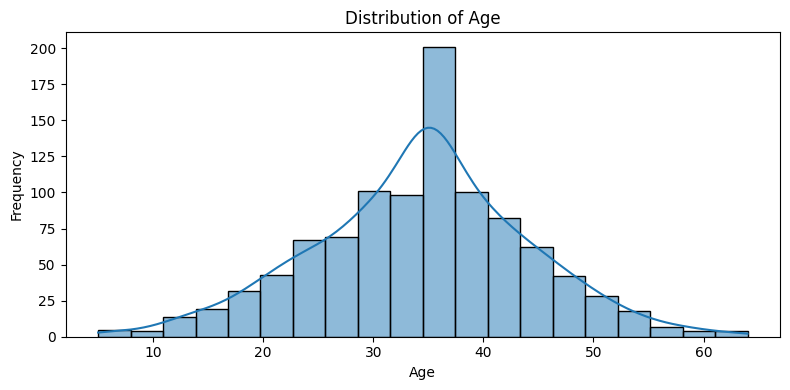

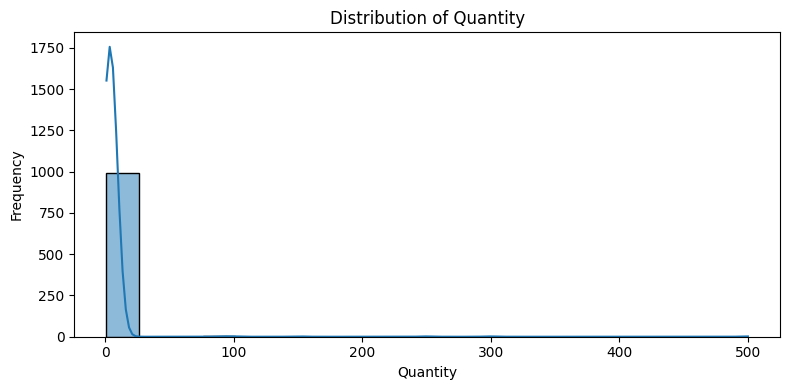

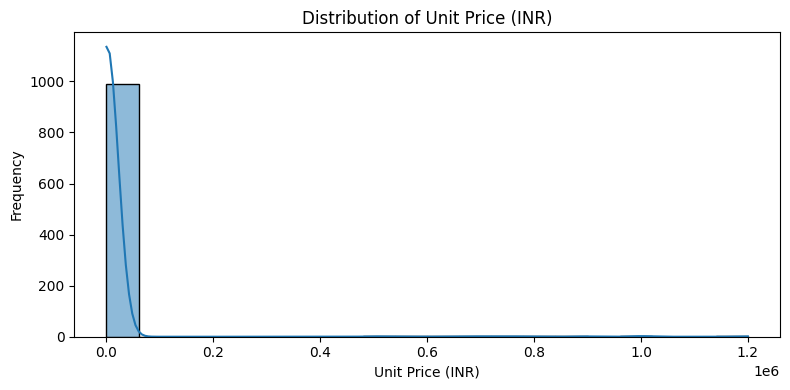

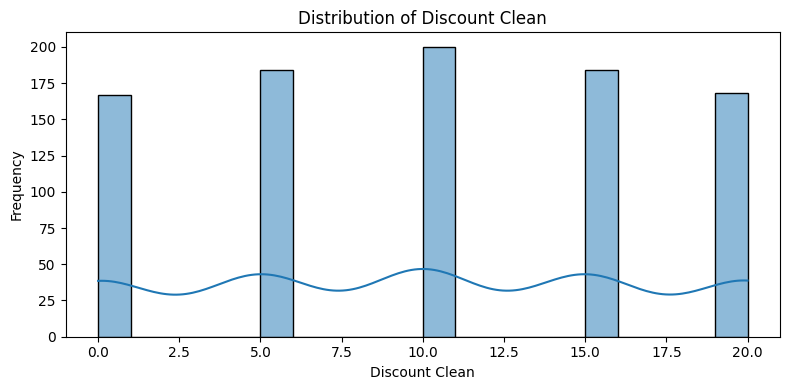

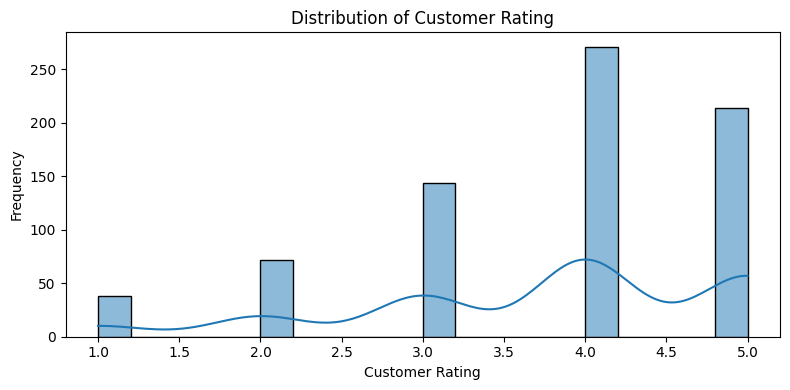

In [ ]:
# Select numerical columns for distribution analysis
numeric_cols = [
    "Age",
    "Quantity",
    "Unit Price (INR)",
    "Discount Clean",
    "Customer Rating"
]

# Create a histogram and KDE plot for each column
for col in numeric_cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## Correlation Analysis

Correlation analysis examines the strength and direction of linear relationships between numerical variables. A correlation matrix summarizes these relationships, while a heatmap provides a visual representation of the correlation coefficients.

This analysis will explore potential relationships between customer age, order quantity, unit price, discount percentage and customer rating. Correlation indicates association, not necessarily causation.

,Age,Quantity,Unit Price (INR),Discount Clean,Customer Rating
Age,1.00,-0.01,0.03,-0.03,0.04
Quantity,-0.01,1.00,-0.01,-0.05,0.02
Unit Price (INR),0.03,-0.01,1.00,0.03,0.04
Discount Clean,-0.03,-0.05,0.03,1.00,-0.02
Customer Rating,0.04,0.02,0.04,-0.02,1.00


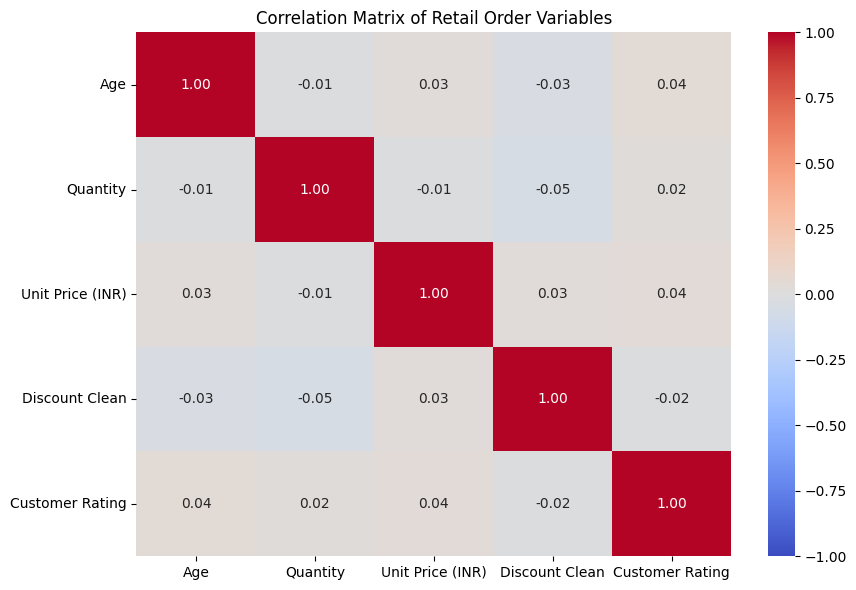

In [8]:
# Select relevant numerical variables
corr_cols = [
    "Age",
    "Quantity",
    "Unit Price (INR)",
    "Discount Clean",
    "Customer Rating"
]

# Calculate Pearson correlation coefficients
corr_matrix = df[corr_cols].corr(method="pearson")

# Display the correlation table
display(corr_matrix.round(2))

# Create the heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix of Retail Order Variables")
plt.tight_layout()
plt.show()

### Correlation Analysis — Findings

The correlation matrix shows that all pairwise correlations between the selected numerical variables are very weak, with coefficients ranging approximately from -0.05 to +0.04. The strongest negative correlation is between Quantity and Discount Clean (-0.05), while the strongest positive correlations shown include Age and Customer Rating, and Unit Price and Customer Rating (+0.04).

These results indicate that no meaningful linear relationships are apparent among the selected variables in the current analysis. However, correlation does not establish causation, and weak Pearson correlations do not exclude nonlinear relationships. The findings should also be interpreted cautiously because extreme values and missing observations may affect the analysis.

## Box Plot Analysis

Box plots are used to compare numerical distributions across categories and identify potential outliers. This analysis examines variations in unit prices and order quantities across product categories. The results can help identify categories with different price ranges, order patterns or unusual observations.

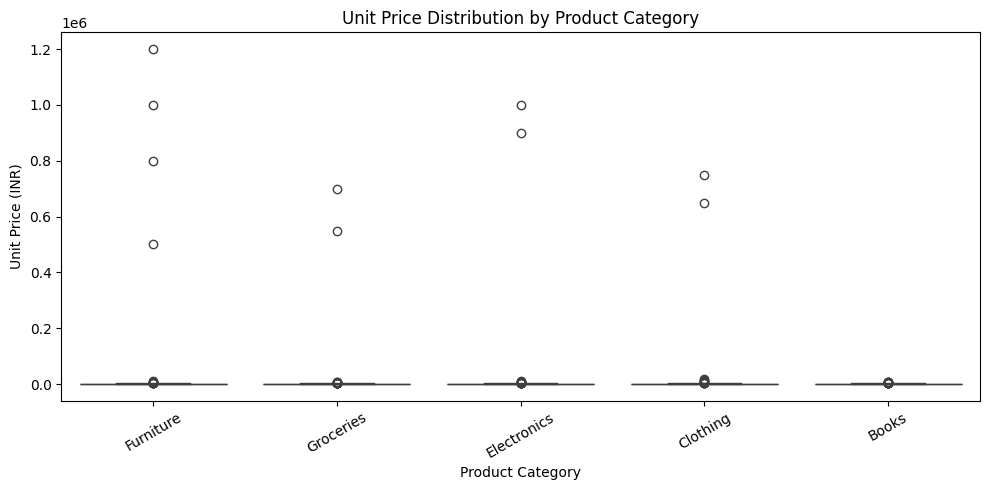

In [9]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Product Category",
    y="Unit Price (INR)"
)

plt.title("Unit Price Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Unit Price (INR)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

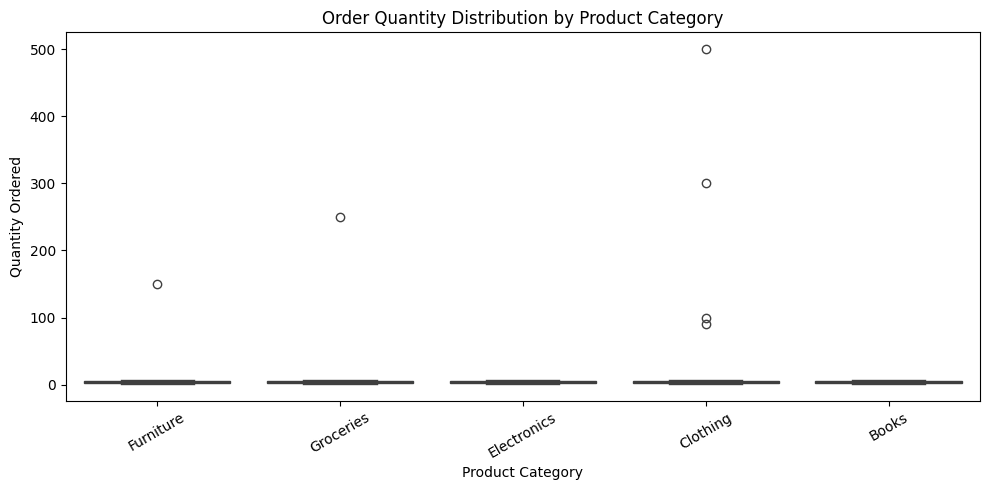

In [10]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Product Category",
    y="Quantity"
)

plt.title("Order Quantity Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Quantity Ordered")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

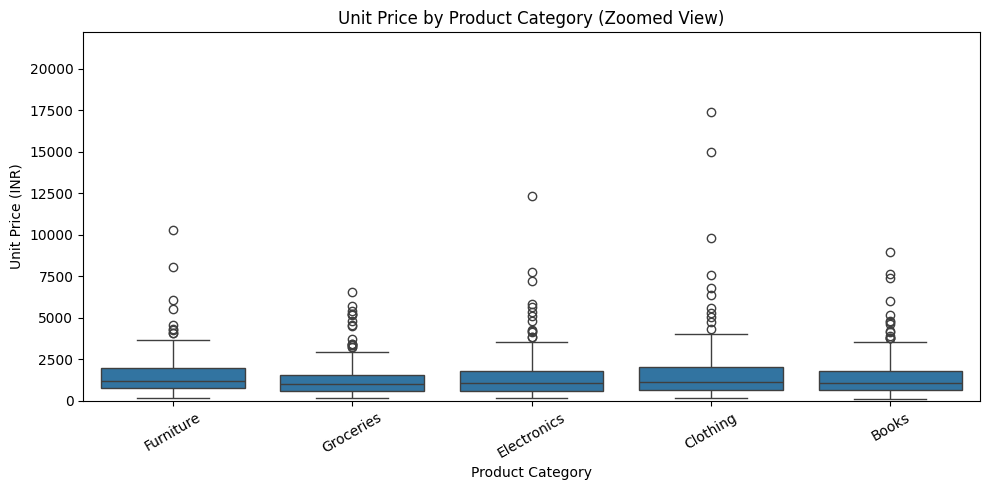

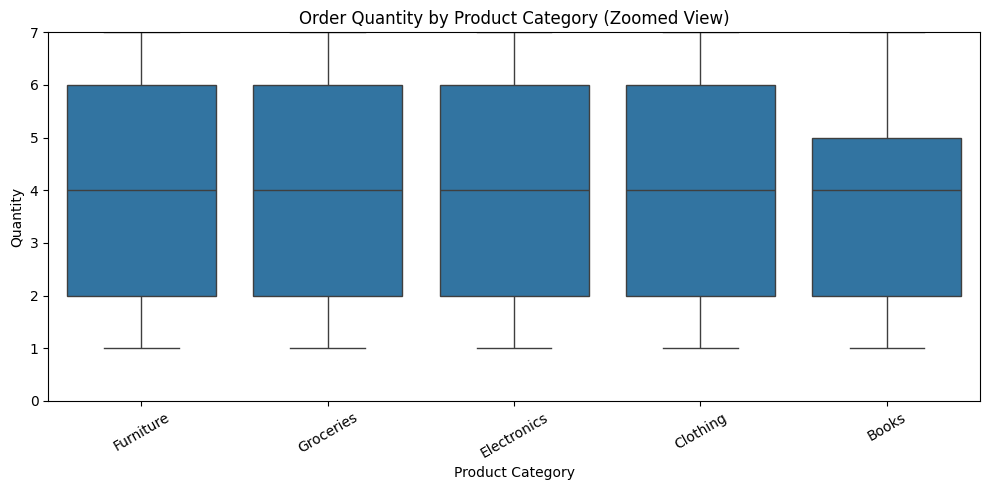

In [11]:
# Zoomed box plot: unit prices
price_limit = df["Unit Price (INR)"].quantile(0.99)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="Product Category",
    y="Unit Price (INR)"
)

plt.ylim(0, price_limit)
plt.title("Unit Price by Product Category (Zoomed View)")
plt.xlabel("Product Category")
plt.ylabel("Unit Price (INR)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Zoomed box plot: order quantities
quantity_limit = df["Quantity"].quantile(0.99)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="Product Category",
    y="Quantity"
)

plt.ylim(0, quantity_limit)
plt.title("Order Quantity by Product Category (Zoomed View)")
plt.xlabel("Product Category")
plt.ylabel("Quantity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Box Plot Analysis — Findings

The box plots reveal extreme values in both unit prices and order quantities across product categories. Furniture, Groceries, Electronics and Clothing contain unusually high unit-price observations. Clothing also contains several unusually large order quantities, including a maximum of 500 units.

These extreme observations compress the central portions of the box plots, making category comparisons difficult. Additional zoomed-in visualizations are used to examine typical values more clearly without deleting records. The unusual observations should be verified against source records to determine whether they represent legitimate bulk purchases, high-value products or data-entry errors.

In [12]:
# Create a separate analysis dataframe
eda_df = df.copy()

# Calculate estimated order value where discount is available
eda_df["Estimated Order Value (INR)"] = (
    eda_df["Quantity"]
    * eda_df["Unit Price (INR)"]
    * (1 - eda_df["Discount Clean"] / 100)
)

# Inspect the calculated values
display(
    eda_df[
        ["Quantity", "Unit Price (INR)",
         "Discount Clean", "Estimated Order Value (INR)"]
    ].head()
)

,Quantity,Unit Price (INR),Discount Clean,Estimated Order Value (INR)
0,2,1042.10,0.0,2084.200
1,7,715.80,10.0,4509.540
2,7,787.70,20.0,4411.120
3,7,1223.53,0.0,8564.710
4,1,1112.13,20.0,889.704


In [13]:
category_summary = eda_df.groupby("Product Category").agg(
    Number_of_Orders=("Order ID", "count"),
    Total_Quantity=("Quantity", "sum"),
    Average_Quantity=("Quantity", "mean"),
    Median_Unit_Price=("Unit Price (INR)", "median"),
    Estimated_Order_Value=("Estimated Order Value (INR)", "sum")
).round(2)

display(
    category_summary.sort_values(
        "Estimated_Order_Value",
        ascending=False
    )
)

,Number_of_Orders,Total_Quantity,Average_Quantity,Median_Unit_Price,Estimated_Order_Value
Product Category,,,,,
Groceries,194,1011,5.21,983.07,7408604.86
Furniture,210,920,4.38,1172.58,6495742.71
Clothing,212,1805,8.51,1142.47,5429203.93
Electronics,191,731,3.83,1054.91,4766919.01
Books,193,733,3.80,1096.87,851396.89


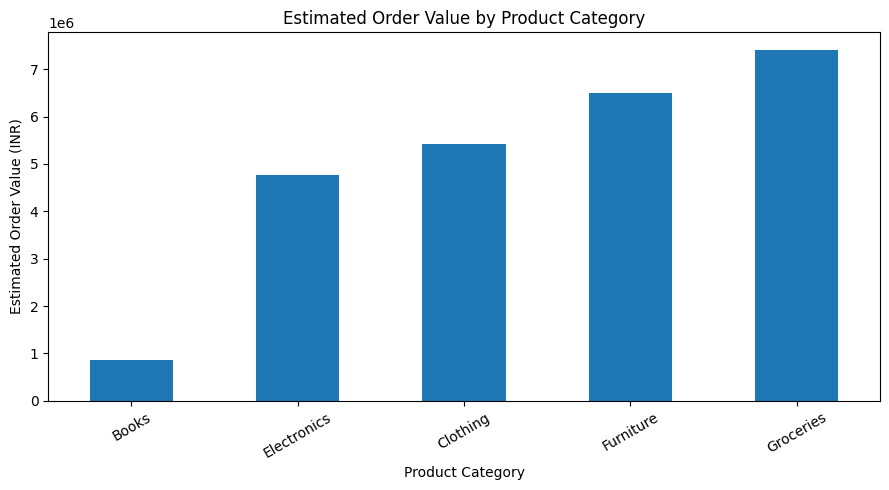

In [14]:
category_summary["Estimated_Order_Value"].sort_values().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Estimated Order Value by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Estimated Order Value (INR)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Time-Series Analysis

Time-series analysis examines how a variable changes over time. The order dates are grouped by month to compare gross order value before discounts across the available observation period.

Gross order value is calculated as quantity multiplied by unit price. Orders with missing dates are excluded because they cannot be assigned to a month. The analysis describes recorded order values and does not necessarily represent finalized accounting revenue.

In [15]:
# Create gross order value before discounts
eda_df["Gross Order Value (INR)"] = (
    eda_df["Quantity"] * eda_df["Unit Price (INR)"]
)

# Exclude records without a valid order date
dated_df = eda_df.dropna(subset=["Order Date"]).copy()

# Group gross order value by month
monthly_summary = (
    dated_df.set_index("Order Date")
    .resample("ME")["Gross Order Value (INR)"]
    .agg(["sum", "count"])
)

monthly_summary.columns = [
    "Gross Order Value (INR)",
    "Number of Orders"
]

display(monthly_summary.round(2))

,Gross Order Value (INR),Number of Orders
Order Date,,
2025-01-31,7139701.64,77
2025-02-28,4806523.08,81
2025-03-31,380650.88,68
2025-04-30,3400051.74,75
2025-05-31,418325.00,76
2025-06-30,4072533.04,68
2025-07-31,973897.28,96
2025-08-31,2588298.57,92
2025-09-30,1507624.97,87


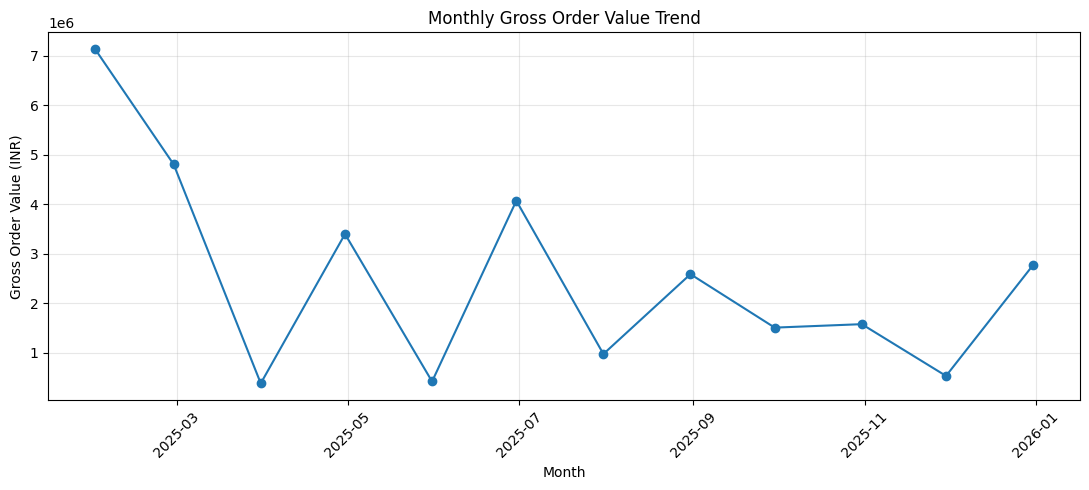

In [16]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_summary.index,
    monthly_summary["Gross Order Value (INR)"],
    marker="o"
)

plt.title("Monthly Gross Order Value Trend")
plt.xlabel("Month")
plt.ylabel("Gross Order Value (INR)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

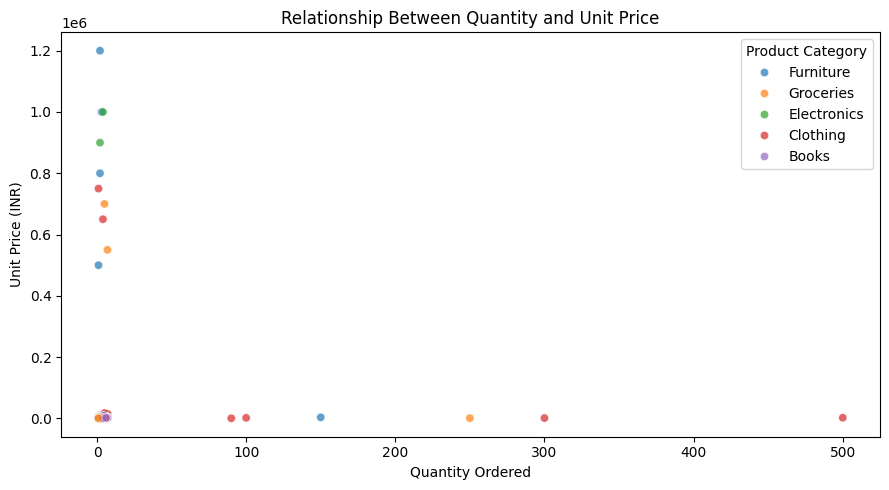

In [17]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Unit Price (INR)",
    hue="Product Category",
    alpha=0.7
)

plt.title("Relationship Between Quantity and Unit Price")
plt.xlabel("Quantity Ordered")
plt.ylabel("Unit Price (INR)")
plt.tight_layout()
plt.show()

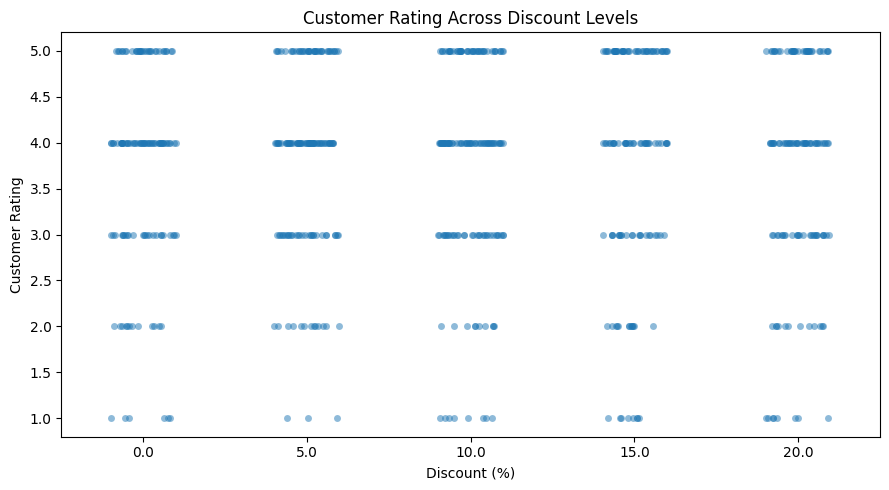

In [18]:
plt.figure(figsize=(9, 5))

sns.stripplot(
    data=df,
    x="Discount Clean",
    y="Customer Rating",
    alpha=0.5,
    jitter=0.2
)

plt.title("Customer Rating Across Discount Levels")
plt.xlabel("Discount (%)")
plt.ylabel("Customer Rating")
plt.tight_layout()
plt.show()

### Scatter Plot Analysis — Findings

**Quantity versus Unit Price:** The scatter plot contains several extreme observations, including unit prices reaching ₹12,00,000 and quantities reaching 500 units. Most observations are concentrated near the lower ends of the axes. No clear linear relationship is visually apparent, although the extreme values make the relationship difficult to assess. Further investigation of these records is recommended.

**Customer Rating versus Discount:** Ratings from 1 to 5 occur across all five discount levels. Ratings of 4 and 5 appear frequently, but the scatter plot does not show an obvious pattern of ratings increasing consistently with discounts. Grouped rating statistics should be calculated to compare the average ratings and number of observations at each discount level.

These visualizations identify patterns for further investigation but do not establish causation.

In [19]:
# Compare customer ratings across discount levels
rating_by_discount = (
    df.groupby("Discount Clean")
    .agg(
        Average_Rating=("Customer Rating", "mean"),
        Number_of_Ratings=("Customer Rating", "count"),
        Median_Rating=("Customer Rating", "median")
    )
    .round(2)
)

display(rating_by_discount)

,Average_Rating,Number_of_Ratings,Median_Rating
Discount Clean,,,
0.0,3.73,126,4.0
5.0,3.83,145,4.0
10.0,3.79,151,4.0
15.0,3.80,125,4.0
20.0,3.68,123,4.0


In [20]:
# Display unusually large quantities and unit prices
extreme_records = df[
    (df["Quantity"] > 50) |
    (df["Unit Price (INR)"] > 10000)
]

display(
    extreme_records[
        [
            "Order ID",
            "Product Category",
            "Quantity",
            "Unit Price (INR)",
            "Discount Clean",
            "Order Date"
        ]
    ].sort_values(
        "Unit Price (INR)",
        ascending=False
    )
)

,Order ID,Product Category,Quantity,Unit Price (INR),Discount Clean,Order Date
944,ORD1308,Furniture,2,1200000.00,10.0,2025-12-18
480,ORD1578,Electronics,4,1000000.00,5.0,2025-02-11
395,ORD1116,Furniture,3,999999.00,20.0,2025-04-11
149,ORD1656,Electronics,2,900000.00,NaN,NaT
171,ORD1646,Furniture,2,800000.00,NaN,2025-08-30
703,ORD1302,Clothing,1,750000.00,5.0,2025-10-31
253,ORD1773,Groceries,5,700000.00,5.0,2025-06-19
548,ORD1153,Clothing,4,650000.00,20.0,2025-01-18
191,ORD1610,Groceries,7,550000.00,20.0,2025-01-28
114,ORD1589,Furniture,1,500000.00,15.0,2025-07-11


In [21]:
# Calculate gross order value for each order
eda_df["Gross Order Value (INR)"] = (
    eda_df["Quantity"] * eda_df["Unit Price (INR)"]
)

# Define a screening rule for unusually large values
extreme_mask = (
    (eda_df["Quantity"] > 50) |
    (eda_df["Unit Price (INR)"] > 10000)
)

# Compare the totals without altering the original data
comparison = pd.DataFrame({
    "Analysis": [
        "All records",
        "Records excluding flagged extremes"
    ],
    "Number of Orders": [
        len(eda_df),
        (~extreme_mask).sum()
    ],
    "Gross Order Value (INR)": [
        eda_df["Gross Order Value (INR)"].sum(),
        eda_df.loc[
            ~extreme_mask, "Gross Order Value (INR)"
        ].sum()
    ]
})

display(comparison.round(2))

,Analysis,Number of Orders,Gross Order Value (INR)
0,All records,1000,32101023.94
1,Records excluding flagged extremes,980,5467789.88
